# Black-Scholes Greeks Along a Simulated Price Path

This notebook computes the Greeks of a European option, i.e. the sensitivities of its price to the
model parameters, and shows how they evolve along a simulated path of the underlying.

**Notation**

* $S_0$: initial price of the underlying
* $K$: strike price
* $\sigma$: volatility
* $r$: risk-free interest rate
* $q$: continuous dividend yield
* $T$: maturity of the option (in years)
* $N$: number of time steps
* $\tau = T - t$: time to maturity

All Greeks use

$$
d_1 = \frac{\ln(S/K) + (r - q + \sigma^2/2)\,\tau}{\sigma\sqrt{\tau}}, \qquad d_2 = d_1 - \sigma\sqrt{\tau}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(seed=7)  # fixed seed for reproducible paths

## Simulating the underlying

The underlying follows a geometric Brownian motion. On each time step of length $\Delta t$:

$$
S_{t+\Delta t} = S_t \exp\left(\left(r - q - \tfrac{\sigma^2}{2}\right)\Delta t + \sigma\sqrt{\Delta t}\,Z\right), \qquad Z \sim \mathcal{N}(0,1)
$$

In [ ]:
def simulate_path(S0, sigma, r, q, T, N, rng=rng):
    dt = T / N
    Z = rng.standard_normal(N)  # one standard normal shock per time step
    # Log-return of the GBM over each step
    log_increments = (r - q - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    # Cumulative log-returns; the leading 0 keeps S[0] = S0
    S = S0 * np.exp(np.concatenate([[0.0], np.cumsum(log_increments)]))
    t = np.linspace(0, T, N + 1)  # N steps -> N + 1 dates from 0 to T
    return t, S


def d1_d2(S, tau, K, sigma, r, q):
    # Black-Scholes d1 and d2 (requires tau > 0)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return d1, d1 - sigma * np.sqrt(tau)


def plot_path_and_greeks(t, S, K, greeks):
    # First panel: the path; then one panel per Greek
    # greeks: dict {name: array of values along the path}
    n_plots = 1 + len(greeks)
    plt.figure(figsize=(7 * n_plots, 5))

    plt.subplot(1, n_plots, 1)
    plt.plot(t, S)
    plt.axhline(y=K, color="r", linestyle="--", label="Strike price")
    plt.xlabel("Time (years)")
    plt.ylabel("Underlying price ($)")
    plt.title("Path of the underlying")
    plt.legend(loc="best")

    for i, (name, values) in enumerate(greeks.items(), start=2):
        plt.subplot(1, n_plots, i)
        plt.plot(t, values)
        plt.xlabel("Time (years)")
        plt.ylabel(name)
        plt.title(f"{name} over time")

    plt.tight_layout()
    plt.show()

Example of a simulated path:

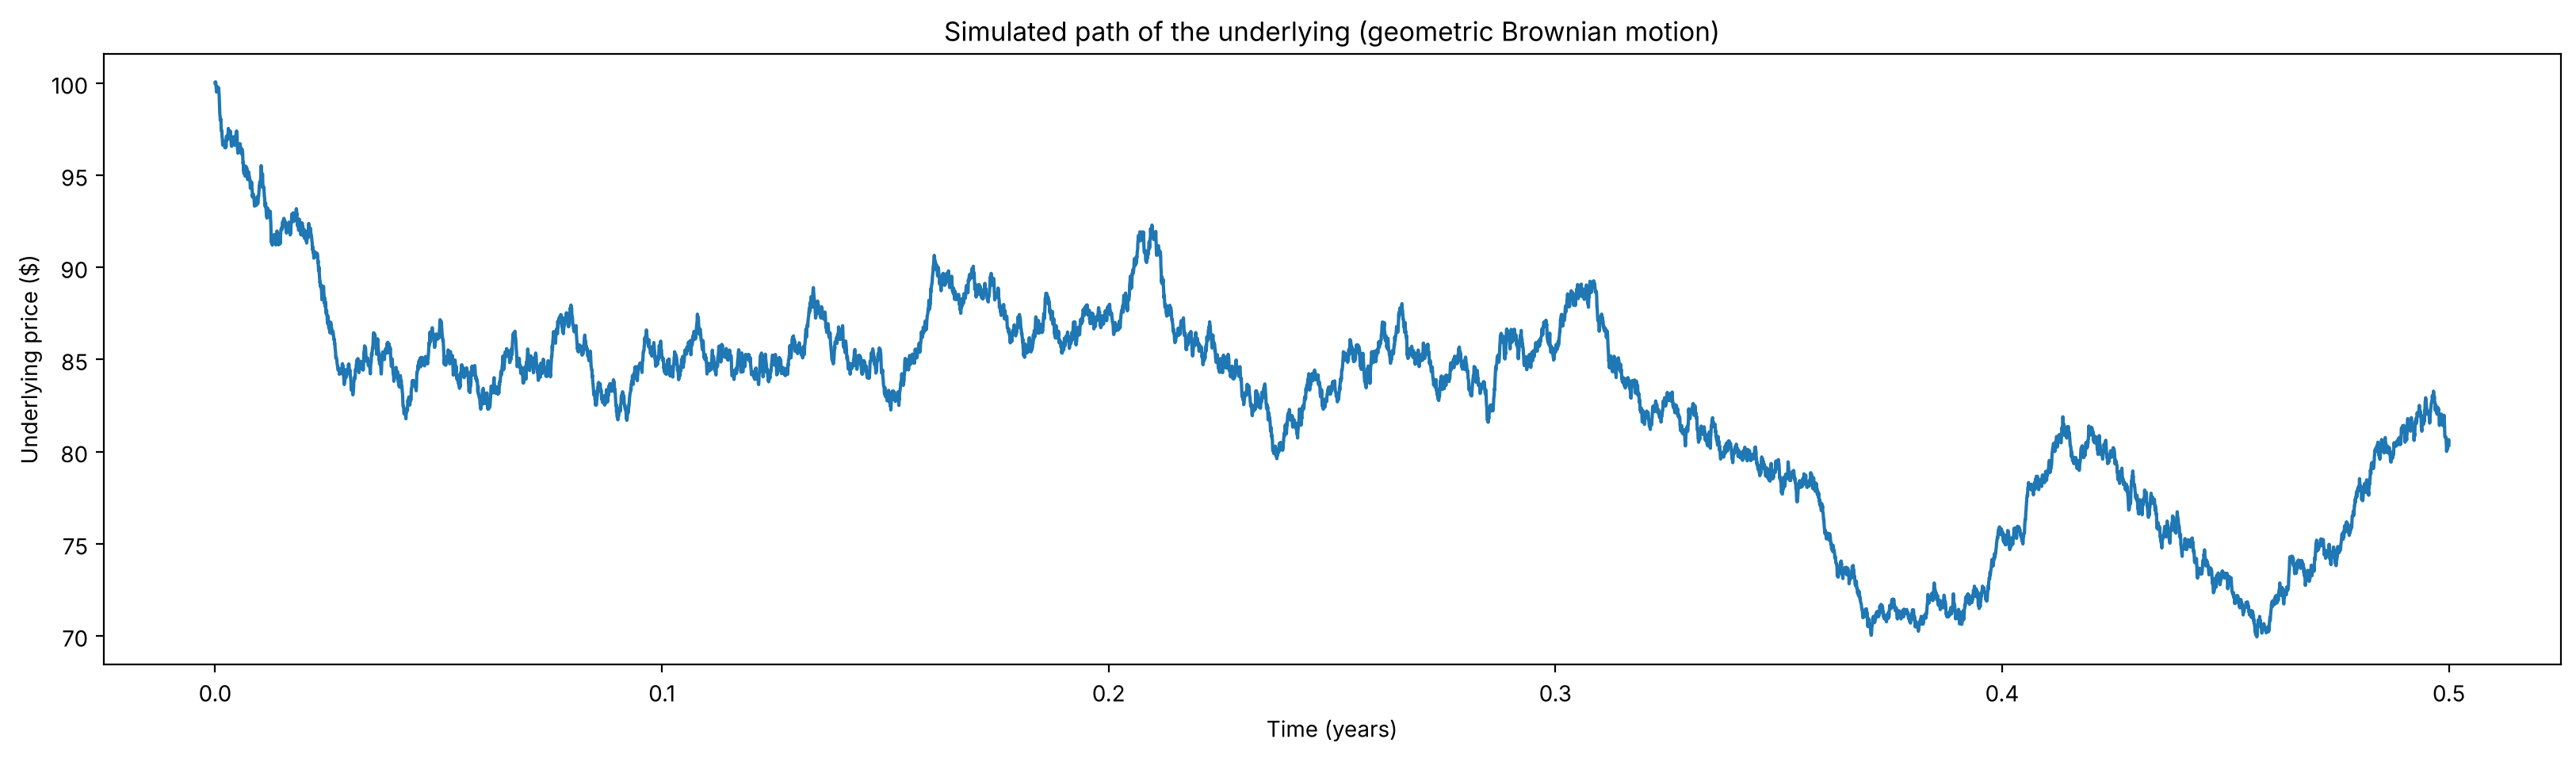

In [3]:
t, prices = simulate_path(S0=100, sigma=0.30, r=0.15, q=0.02, T=0.5, N=10_000)

plt.figure(figsize=(20, 5))
plt.plot(t, prices)
plt.xlabel("Time (years)")
plt.ylabel("Underlying price ($)")
plt.title("Simulated path of the underlying (geometric Brownian motion)")
plt.show()

## Delta ($\Delta$)

Sensitivity of the option price to the price of the underlying:

$$
\Delta_{call} = e^{-q\tau} N(d_1), \qquad \Delta_{put} = e^{-q\tau}\left(N(d_1) - 1\right)
$$

At maturity ($\tau = 0$), Delta jumps to 1 or 0 for a call (0 or $-1$ for a put) depending on whether the option expires in the money.

In [ ]:
def delta(S, t, K, sigma, r, q, T, option_type="call"):
    tau = T - t  # time to maturity at each date
    out = np.zeros_like(S)
    # Dates before expiry: the formula divides by sqrt(tau), so tau = 0 is handled separately
    alive = tau > 1e-10
    d1, _ = d1_d2(S[alive], tau[alive], K, sigma, r, q)

    if option_type == "call":
        out[alive] = np.exp(-q * tau[alive]) * norm.cdf(d1)
        # At expiry: 1 if the call is in the money (S > K), 0 otherwise
        out[~alive] = (S[~alive] > K).astype(float)
    elif option_type == "put":
        out[alive] = np.exp(-q * tau[alive]) * (norm.cdf(d1) - 1)
        # At expiry: -1 if the put is in the money (S < K), 0 otherwise
        out[~alive] = -(S[~alive] < K).astype(float)
    return out

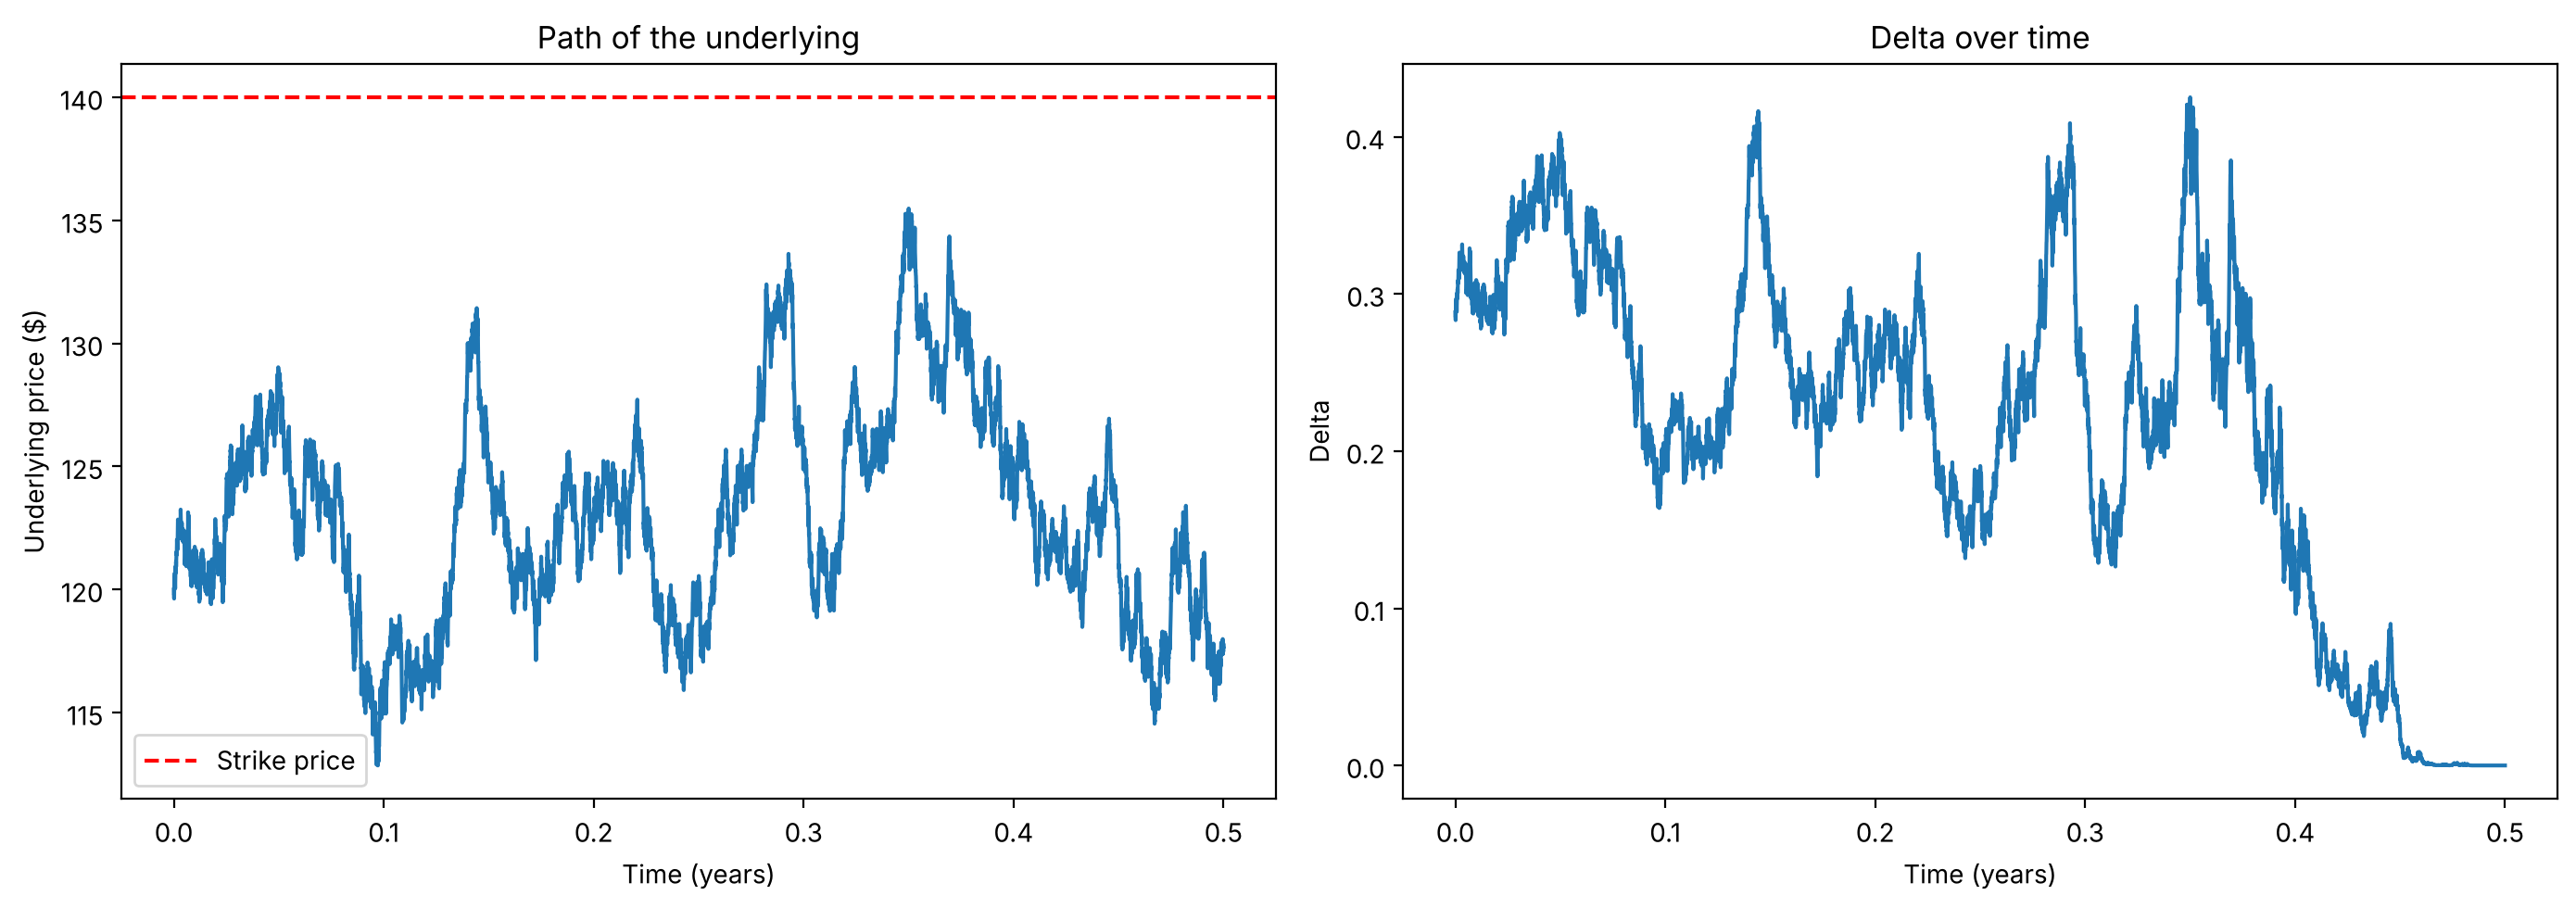

In [5]:
# Parameters
S0 = 120
K = 140
sigma = 0.3
r = 0.05
q = 0.02
T = 0.5
N = 10000
option_type = "call"

t, S = simulate_path(S0, sigma, r, q, T, N)
delta_values = delta(S, t, K, sigma, r, q, T, option_type)

plot_path_and_greeks(t, S, K, {"Delta": delta_values})

## Gamma ($\Gamma$)

Sensitivity of Delta to the price of the underlying (identical for calls and puts):

$$
\Gamma = \frac{e^{-q\tau}\, N'(d_1)}{S\,\sigma\sqrt{\tau}}
$$

Comparison of the underlying, Delta and Gamma over time:

In [ ]:
def gamma(S, t, K, sigma, r, q, T, option_type="call"):
    # option_type is unused (same Gamma for calls and puts); kept for a common signature
    tau = T - t
    out = np.zeros_like(S)  # Gamma is 0 at expiry (except exactly at S = K)
    alive = tau > 1e-10  # dates before expiry (the formula divides by sqrt(tau))
    d1, _ = d1_d2(S[alive], tau[alive], K, sigma, r, q)
    out[alive] = np.exp(-q * tau[alive]) * norm.pdf(d1) / (S[alive] * sigma * np.sqrt(tau[alive]))
    return out

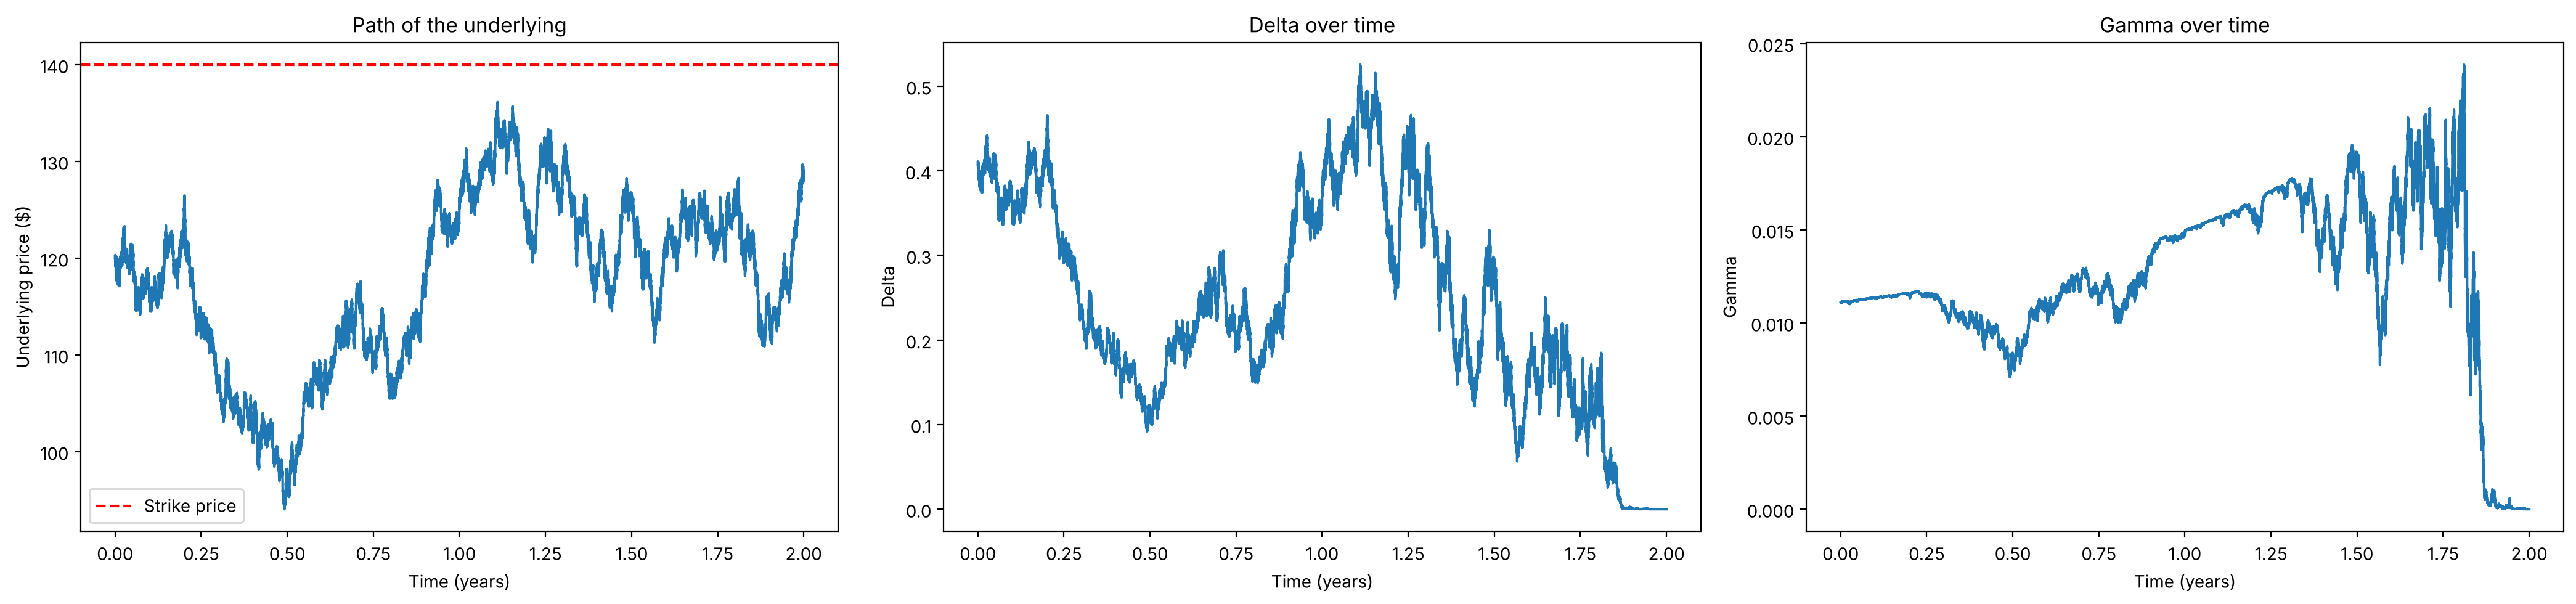

In [7]:
# Parameters
S0 = 120
sigma = 0.2
r = 0.05
q = 0.02
K = 140
T = 2
N = 100_000
option_type = "call"

t, S = simulate_path(S0, sigma, r, q, T, N)
delta_values = delta(S, t, K, sigma, r, q, T, option_type)
gamma_values = gamma(S, t, K, sigma, r, q, T, option_type)

plot_path_and_greeks(t, S, K, {"Delta": delta_values, "Gamma": gamma_values})

## Theta ($\Theta$)

Sensitivity of the option price to the passage of time (per year):

$$
\Theta_{call} = -\frac{S e^{-q\tau} N'(d_1)\,\sigma}{2\sqrt{\tau}} + q S e^{-q\tau} N(d_1) - r K e^{-r\tau} N(d_2)
$$

$$
\Theta_{put} = -\frac{S e^{-q\tau} N'(d_1)\,\sigma}{2\sqrt{\tau}} - q S e^{-q\tau} N(-d_1) + r K e^{-r\tau} N(-d_2)
$$

In [ ]:
def theta(S, t, K, sigma, r, q, T, option_type="call"):
    tau = T - t
    out = np.zeros_like(S)  # expired dates are left at 0 (convention)
    alive = tau > 1e-10  # dates before expiry (the formula divides by sqrt(tau))
    S_a, tau_a = S[alive], tau[alive]  # values before expiry only
    d1, d2 = d1_d2(S_a, tau_a, K, sigma, r, q)

    # This first term is the same for calls and puts
    common_term = -(S_a * np.exp(-q * tau_a) * norm.pdf(d1) * sigma) / (2 * np.sqrt(tau_a))

    if option_type == "call":
        out[alive] = common_term + q * S_a * np.exp(-q * tau_a) * norm.cdf(d1) - r * K * np.exp(-r * tau_a) * norm.cdf(d2)
    elif option_type == "put":
        out[alive] = common_term - q * S_a * np.exp(-q * tau_a) * norm.cdf(-d1) + r * K * np.exp(-r * tau_a) * norm.cdf(-d2)
    return out

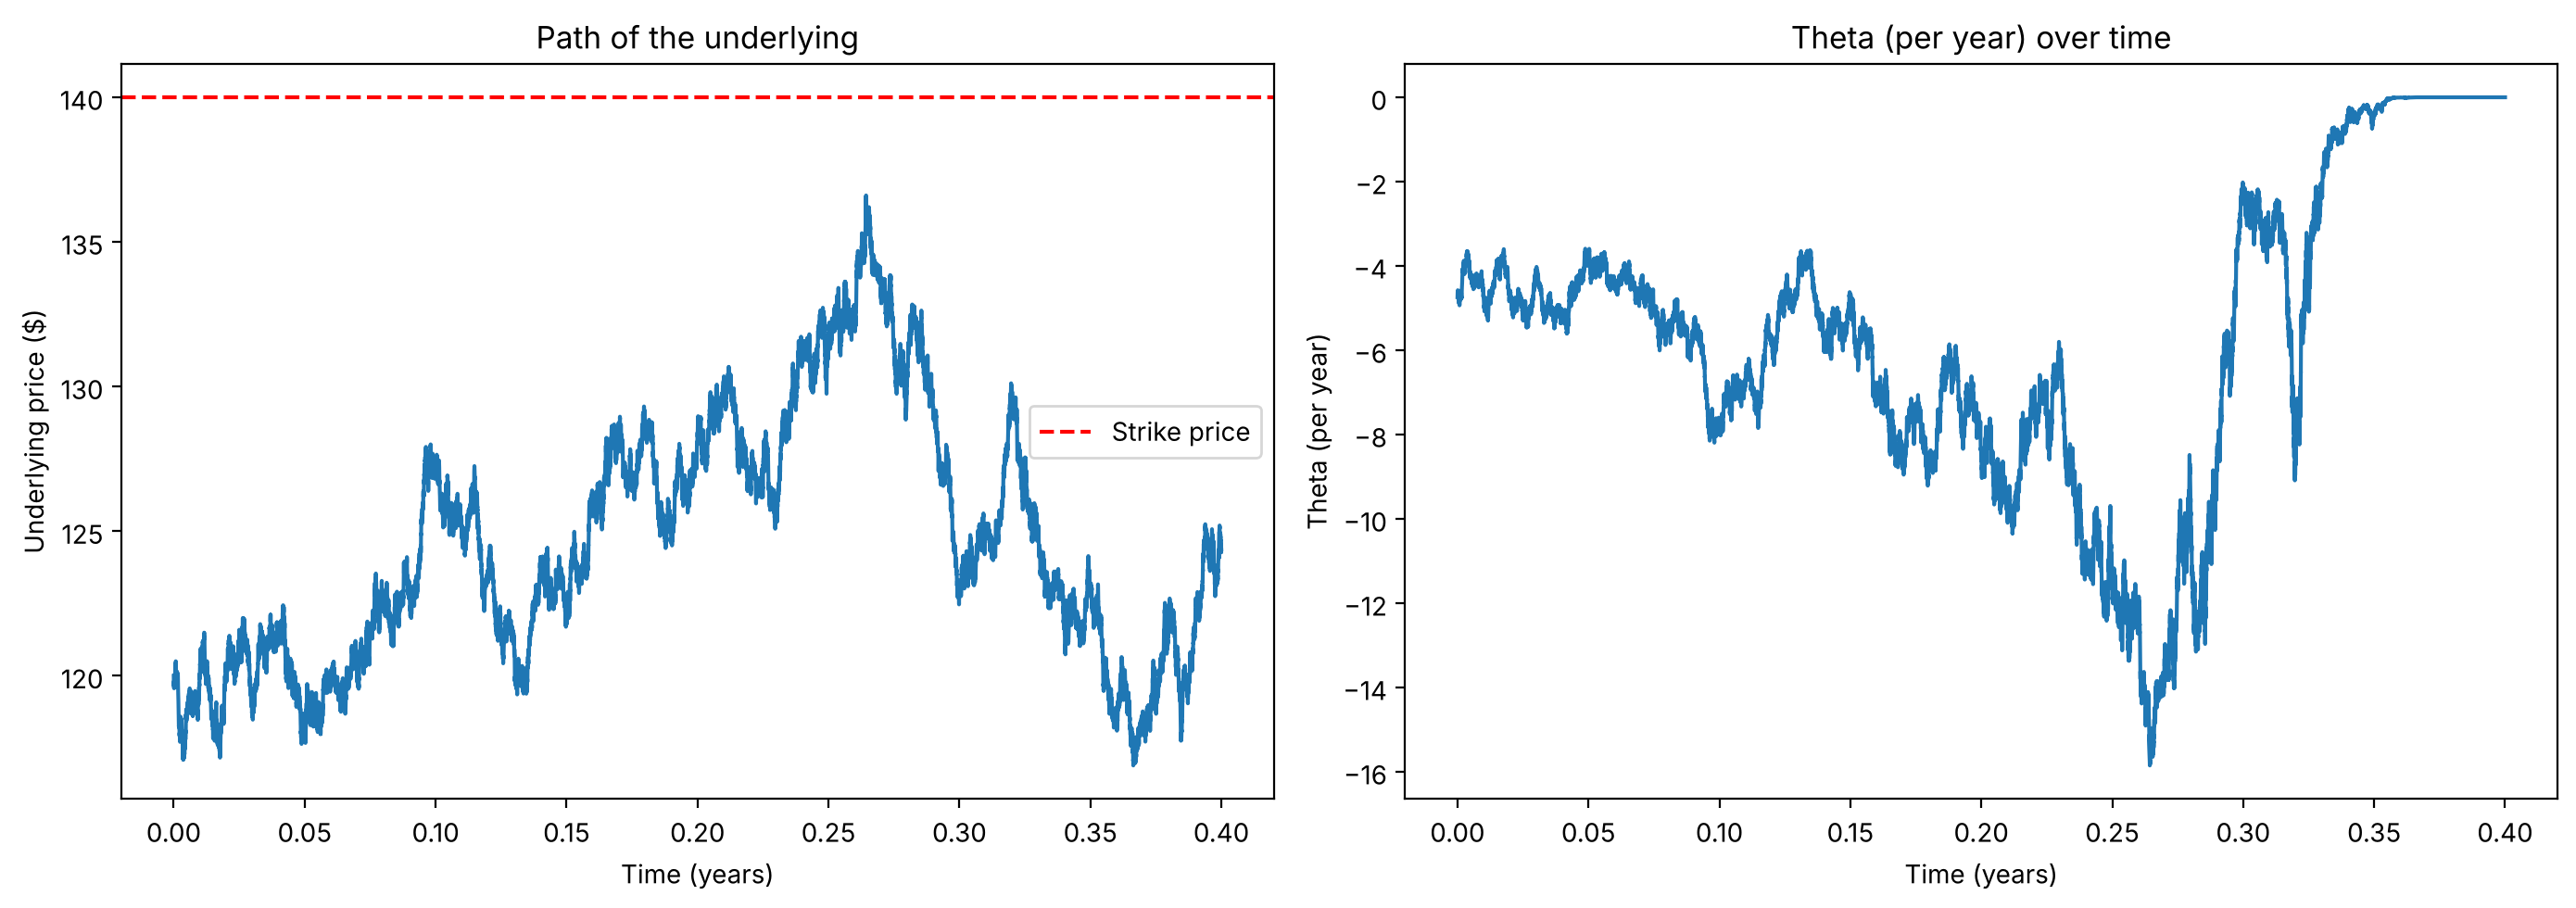

In [9]:
# Parameters
S0 = 120
K = 140
sigma = 0.2
r = 0.05
q = 0.02
T = 0.4
N = 25000
option_type = "call"

t, S = simulate_path(S0, sigma, r, q, T, N)
theta_values = theta(S, t, K, sigma, r, q, T, option_type)

plot_path_and_greeks(t, S, K, {"Theta (per year)": theta_values})

## Vega ($\nu$)

Sensitivity of the option price to volatility (identical for calls and puts):

$$
\nu = S e^{-q\tau} \sqrt{\tau}\, N'(d_1)
$$

This is the price change for a change of 1 (i.e. 100 volatility points) in $\sigma$; divide by 100 for the change per volatility point.

In [ ]:
def vega(S, t, K, sigma, r, q, T, option_type="call"):
    # option_type is unused (same Vega for calls and puts); kept for a common signature
    tau = T - t
    out = np.zeros_like(S)  # Vega is 0 at expiry
    alive = tau > 1e-10  # dates before expiry
    d1, _ = d1_d2(S[alive], tau[alive], K, sigma, r, q)
    out[alive] = S[alive] * np.exp(-q * tau[alive]) * np.sqrt(tau[alive]) * norm.pdf(d1)
    return out

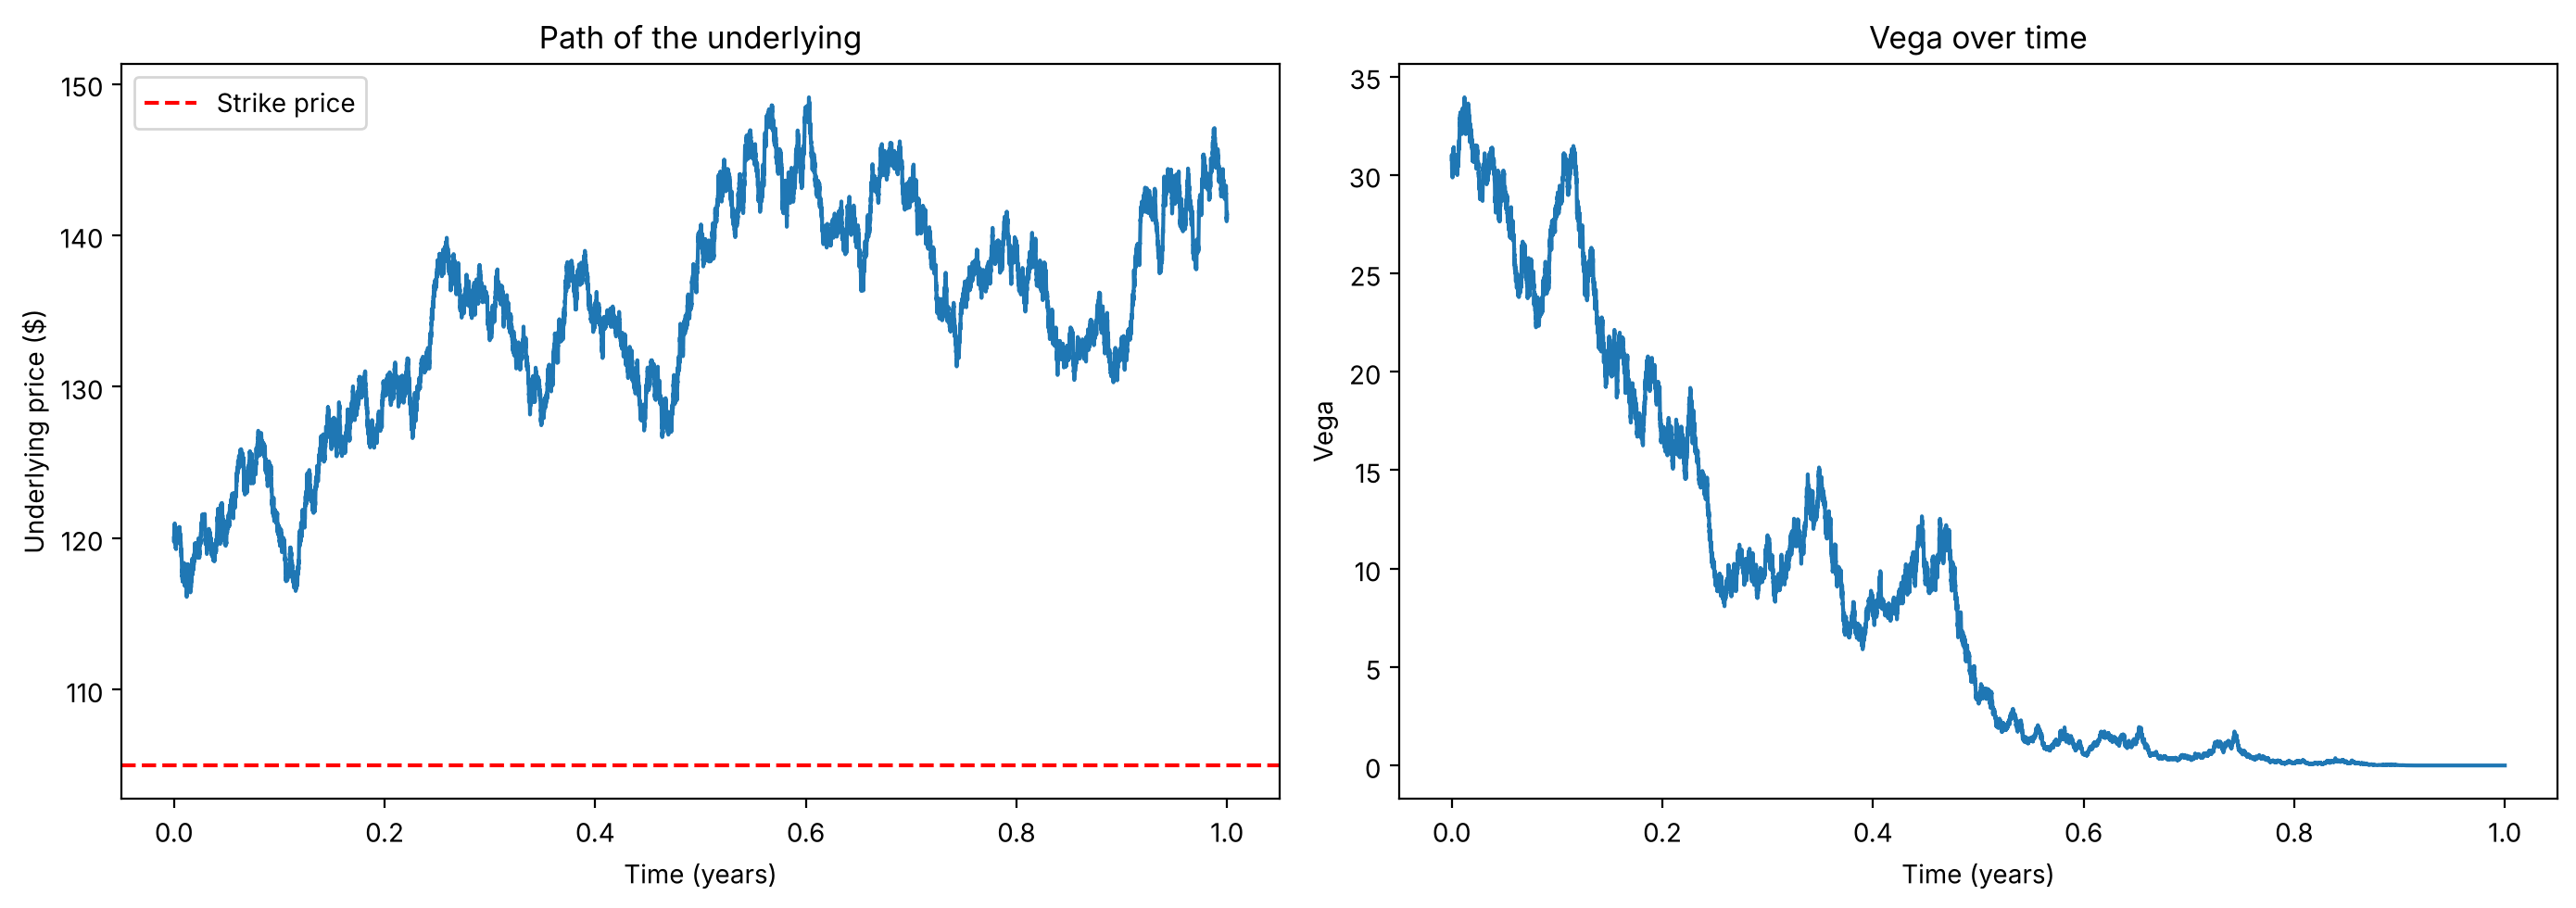

In [11]:
# Parameters
S0 = 120
K = 105
sigma = 0.2
r = 0.05
q = 0.02
T = 1
N = 25000
option_type = "call"

t, S = simulate_path(S0, sigma, r, q, T, N)
vega_values = vega(S, t, K, sigma, r, q, T, option_type)

plot_path_and_greeks(t, S, K, {"Vega": vega_values})

## Rho ($\rho$)

Sensitivity of the option price to the risk-free rate:

$$
\rho_{call} = K\tau e^{-r\tau} N(d_2), \qquad \rho_{put} = -K\tau e^{-r\tau} N(-d_2)
$$

In [ ]:
def rho(S, t, K, sigma, r, q, T, option_type="call"):
    tau = T - t
    out = np.zeros_like(S)  # Rho is 0 at expiry (it is proportional to tau)
    alive = tau > 1e-10  # dates before expiry
    _, d2 = d1_d2(S[alive], tau[alive], K, sigma, r, q)

    if option_type == "call":
        out[alive] = K * tau[alive] * np.exp(-r * tau[alive]) * norm.cdf(d2)
    elif option_type == "put":
        out[alive] = -K * tau[alive] * np.exp(-r * tau[alive]) * norm.cdf(-d2)
    return out

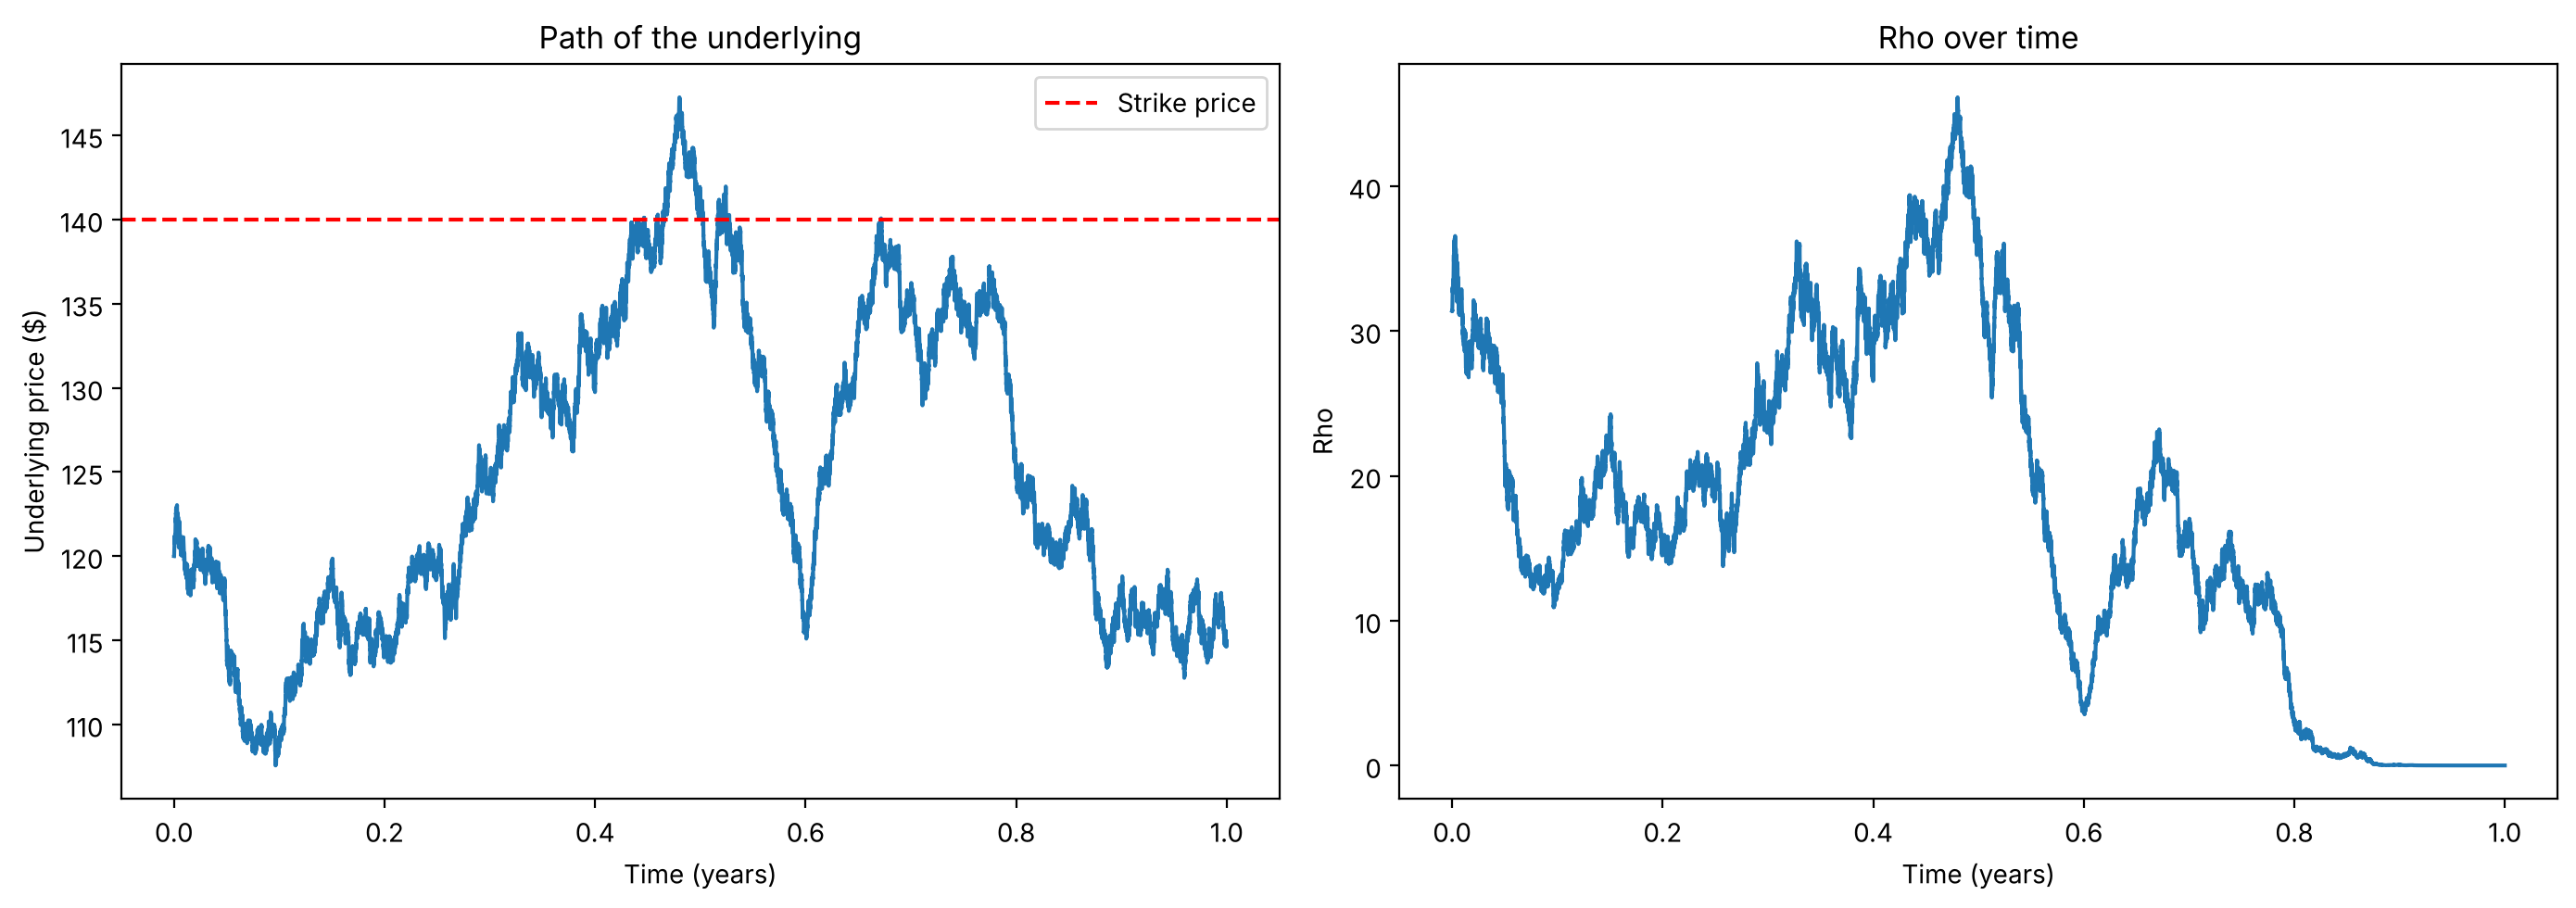

In [13]:
# Parameters
S0 = 120
K = 140
sigma = 0.2
r = 0.05
q = 0.02
T = 1
N = 25000
option_type = "call"

t, S = simulate_path(S0, sigma, r, q, T, N)
rho_values = rho(S, t, K, sigma, r, q, T, option_type)

plot_path_and_greeks(t, S, K, {"Rho": rho_values})